Single allele groupped structue models.

In [294]:
import pomegranate.io
from pomegranate import *

In [295]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
import seaborn as sns
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [296]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/core_identification_paper/per_length_per_kfold_split/' # work laptop
TARGET_PATH_TO_RESULTS = "experiment_results/batched_and_chains/" #!CHANGE for bwv!

In [297]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

print(sorted(ALLELES))

['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-A*24:02', 'HLA-B*07:02', 'HLA-B*15:02', 'HLA-B*27:05', 'HLA-B*57:01', 'HLA-C*12:02', 'HLA-DPA1*02:02/DPB1*05:01', 'HLA-DQA1*05:01/DQB1*02:01', 'HLA-DRB1*01:01', 'HLA-DRB1*04:01', 'HLA-DRB1*04:04', 'HLA-DRB1*07:01']


In [298]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations and define params

In [299]:

# Training params
algorithm = 'viterbi'
combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 3
USE_WEIGHTS = False
check_peptides = True
target_class = "class2_batches"
params = dict()


DataParams = {
"class1": {
    "ALLELES": sorted([ 'HLA-A*01:01','HLA-A*03:01']),
    "TARGET_LENGTHS":   [8, 9,10, 11, 12],
    'start_cycle': False,
    'end_cycle' :False,
    'intermediate_cycles' :True,
    'emission_pseudocount':50,
    'transition_pseudocount' : 0,
    'in_cycle_tr_pseudocount' : 30,
    'anchor_top_aas':3,
    'anchor_default_pseudocount':50
},
    
"class2": {
    "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13,14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':50,
    'transition_pseudocount' : 50,

    'anchor_top_aas':6,
    'anchor_default_pseudocount': 50,
    'in_cycle_tr_pseudocount' : 300,

    
},
    "class2_batches": {
     "ALLELES":sorted([ 'HLA-DPA1*02:02/DPB1*05:01']),
  #  "ALLELES":sorted(['HLA-DPA1*02:02/DPB1*05:01']),
    "TARGET_LENGTHS":    [12, 13, 14, 15, 16,17, 18],
    'start_cycle': True,
    'end_cycle' : True,
    'intermediate_cycles' :False,
    'emission_pseudocount':1,
    'transition_pseudocount' : 1,

    'anchor_top_aas':6,
    'anchor_default_pseudocount': 1,
    'in_cycle_tr_pseudocount' : 0,
    'cycle_top_aas':20,
    'cycle_default_pseudocount': 0.01,
}
}

params['st'] = 21
params['alg'] = algorithm
params['min_iters'] = 1000
params['max_iters'] = 1100
params['emission_pseudocount'] = DataParams[target_class]["emission_pseudocount"]
params['transition_pseudocount'] =  DataParams[target_class]["transition_pseudocount"]
params['verbose'] = True
params['lr_decay'] = 0.0
params['edge_inertia'] = 0.3
params['distribution_inertia'] = 0.3
params['groups'] = 7
params['states_per_group'] = 3
params['model_complexity'] = 3
params['use_pseudocount'] = True

# Class 1 params
params['self_cycle'] = False
params['start_cycle'] = DataParams[target_class]["start_cycle"]
params['end_cycle'] =  DataParams[target_class]["end_cycle"]
params['equal_probs_for_cycle'] = False
params['cycle_top_aas'] =  DataParams[target_class]["cycle_top_aas"]
params['cycle_default_pseudocount'] =  DataParams[target_class]["cycle_default_pseudocount"]

params['freeze_distr'] = False # wether to freeze start and end cycle distributions
params['tie_cycle_states'] = False
params['in_cycle_tr_pseudocount'] =  DataParams[target_class]["in_cycle_tr_pseudocount"]
params['anchor_top_aas'] = DataParams[target_class]["anchor_top_aas"]
params['anchor_states'] = True
params['anchor_default_pseudocount'] =  DataParams[target_class]["anchor_default_pseudocount"]
params['tie_anchor_states'] = False
params['intermediate_cycles'] = DataParams[target_class]["intermediate_cycles"]


params['equal_probs_for_intermediate_cycle'] =False
params['tie_intermediate_cycles'] =False
params['freeze_int_cycle_distr'] =False
params['position_component']=False
params['cycle_chain'] = True

params['minibatch_training'] = True

params['batches_per_epoch'] = 100
params['batch_size'] = 1





params['multiple_check_input'] = False
ALLELES = DataParams[target_class]["ALLELES"]
TARGET_LENGTHS=   DataParams[target_class]["TARGET_LENGTHS"]


assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

initial_params = None



# combination_size = len(ALLELES)
#ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
                  # ])
#ALLELES = sorted([ 'HLA-A*03:01'])


# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DRB1*04:01'])

# sorted(['HLA-DRB1*01:01','HLA-DRB1*04:01','HLA-DPA1*01:03/DPB1*04:01','HLA-DRB1*03:01','HLA-DRB1*15:01', 'HLA-DRB3*01:01',
#  'HLA-DRB5*01:01'])

# ALLELES = sorted([#'HLA-DQA1*05:01/DQB1*02:01', 
#                   'HLA-DPA1*02:02/DPB1*05:01'
#                  ])



In [300]:
params['anchor_default_pseudocount']

1

# Motif for train data

In [301]:
target_allele = ALLELES[0]
{target_length: len(per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]) for target_length in TARGET_LENGTHS}

{12: 420, 13: 790, 14: 1241, 15: 1231, 16: 927, 17: 628, 18: 403}

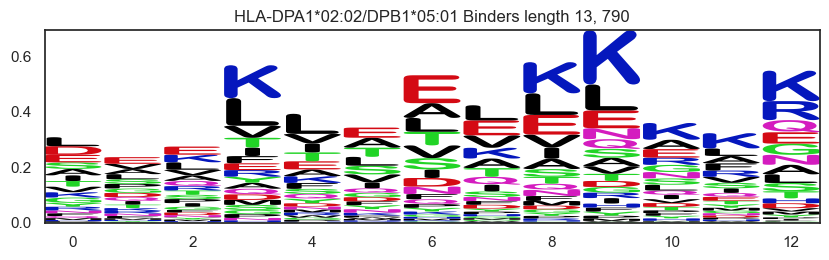

In [302]:
target_length = 13
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, f"{ target_allele} Binders length {target_length}")

# Transform data

In [303]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=None,position_component=params['position_component']
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DPA1*02:02/DPB1*05:01
Length 9: HLA-DPA1*02:02/DPB1*05:01 - 12 
Length 10: HLA-DPA1*02:02/DPB1*05:01 - 53 
Length 11: HLA-DPA1*02:02/DPB1*05:01 - 204 
Length 12: HLA-DPA1*02:02/DPB1*05:01 - 420 
Length 13: HLA-DPA1*02:02/DPB1*05:01 - 790 
Length 14: HLA-DPA1*02:02/DPB1*05:01 - 1241 
Length 15: HLA-DPA1*02:02/DPB1*05:01 - 1231 
Length 16: HLA-DPA1*02:02/DPB1*05:01 - 927 
Length 17: HLA-DPA1*02:02/DPB1*05:01 - 628 
Length 18: HLA-DPA1*02:02/DPB1*05:01 - 403 
Length 19: HLA-DPA1*02:02/DPB1*05:01 - 232 
Length 20: HLA-DPA1*02:02/DPB1*05:01 - 121 
Length 21: HLA-DPA1*02:02/DPB1*05:01 - 72 
Length 22: HLA-DPA1*02:02/DPB1*05:01 - 36 
Length 23: HLA-DPA1*02:02/DPB1*05:01 - 25 
Length 24: HLA-DPA1*02:02/DPB1*05:01 - 9 
Length 25: HLA-DPA1*02:02/DPB1*05:01 - 10 
Length 26: HLA-DPA1*02:02/DPB1*05:01 - 6 


In [304]:
per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][9][0]

'YPLHTYPKE'

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [305]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [306]:
count_df_train.index.levels

FrozenList([['HLA-DPA1*02:02/DPB1*05:01'], [0, 1, 2, 3, 4], [9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]])

## 2.3 Weights for data based on counts

In [307]:
sub_count_df_train = count_df_train.loc[(count_df_train.index.get_level_values('split') == 0) &
                                        (count_df_train.index.get_level_values('allele').isin(ALLELES)) &
                                        (count_df_train.index.get_level_values('length').isin(TARGET_LENGTHS))]

In [308]:
sub_count_df_train['cnt'].sum()

5640

In [309]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 5640
Weights for lentgh 12 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 13 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 14 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 15 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 16 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 17 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 18 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Devide by 1
Combination HLA-DPA1*02:02/DPB1*05:01, split 0: {12: array([1.]), 13: array([1.]), 14: array([1.]), 15: array([1.]), 16: array([1.]), 17: array([1.]), 18: array([1.])}
Total data length for split 1 is 5640
Weights for lentgh 12 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 13 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 14 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 15 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 16 are {'HLA-DPA1*02:02/DPB1*05:01': 1}
Weights for lentgh 17 are {'HLA-DPA1

## Transform to properties

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [310]:
from hmm_logic_methods import train_model_prepared,  train_model_batched, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles_here



## 2.2 Train
### 2.2.1 Define treshold

In [311]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)

params['stop_threshold'] = stop_threshold

stop_threshold

2.9968214285714287

### 2.2.2 Prepare  initial grouped structure models

In [312]:
prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    IN_CYCLE_TR_PSEUDOCOUNT=params['in_cycle_tr_pseudocount'],
    freeze_distr=params['freeze_distr'],
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    cycle_max_components=params['cycle_top_aas'],
    cycle_default_pseudocount=params['cycle_default_pseudocount'],
    discrete_distribution=check_peptides,
    equal_probs_for_cycle=params['equal_probs_for_cycle'],
    tie_cycle_states=params['tie_cycle_states'],
    anchor_max_components=params['anchor_top_aas'],
    anchor_states=params['anchor_states'],
    model_complexity=params['model_complexity'],
    anchor_default_pseudocount= params['anchor_default_pseudocount'],
    tie_anchor_states=params['tie_anchor_states'],
                    intermediate_cycles=params['intermediate_cycles'],
                    equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                    tie_intermediate_cycles=params['tie_intermediate_cycles'],
                    freeze_int_cycle_distr=params['freeze_int_cycle_distr'],
    position_component=params['position_component'],
    cycle_chain=params['cycle_chain']

)

start cycles added 10
end cycles added 20
states will be groups:21 + joiners:6 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [27, 28, 29, 30, 31, 32, 33, 34, 35, 36]


In [313]:
prepared_model.states[15]

{
    "class" : "State",
    "distribution" : {
        "class" : "Distribution",
        "dtype" : "str",
        "name" : "DiscreteDistribution",
        "parameters" : [
            {
                "A" : 0.08545279010265407,
                "C" : 0.08861065733216054,
                "D" : 0.08306137779949942,
                "E" : 0.02129302204988104,
                "F" : 0.009670933738649459,
                "G" : 0.08859901269751502,
                "H" : 0.01847662709362366,
                "I" : 0.03250387745817365,
                "K" : 0.041375242179002854,
                "L" : 0.061921214022765965,
                "M" : 0.08808743918701632,
                "N" : 0.07291769652034552,
                "P" : 0.039862641385070875,
                "Q" : 0.03339346508960004,
                "R" : 0.08917467945787341,
                "S" : 0.015066193473918868,
                "T" : 0.05270347446391892,
                "V" : 0.02041372719537042,
                "W" : 0.0463808837

In [314]:
from itertools import islice

In [315]:
prepared_model.dense_transition_matrix().shape

(49, 49)

In [316]:
with open('model.png', 'w+') as f:
    prepared_model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [317]:
from hmm_visualization_methods import *
plot_distributions_for_states(prepared_model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [318]:

make_pyviz_graph(prepared_model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=49 |E|=164

In [319]:
peptide = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][18][0]

## Test Batched training here

In [320]:
rng = np.random.default_rng()

In [321]:
per_length_data = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0]
per_length_current_weights = per_allele_per_kfold_per_length_weights[ALLELES[0]][0]
binders_array = np.array([per_length_data[target_length][i] for target_length in TARGET_LENGTHS
                          for i in range(len(per_length_data[target_length]))], dtype=object)
weights_array = np.array([per_length_current_weights[target_length][i] for target_length in TARGET_LENGTHS
                          for i in range(len(per_length_current_weights[target_length]))], dtype=object)

new_indexes = rng.permutation(len(binders_array))
binders_array = binders_array[new_indexes]
weights_array = weights_array[new_indexes]
binders_array[0] , weights_array[0]

('SGVLLILPDVLLE', 1.0)

In [322]:
params['batch_size'], params['batches_per_epoch']

(1, 100)

In [323]:
from pomegranate.io import BatchedDataGenerator, SequenceGenerator
batch_size = 1
batches_per_epoch = 100
## Make batched sequence generator
sample_X = np.array([[char for char in item] for item in binders_array], dtype=object)
sequence_generator = BatchedDataGenerator(sample_X,
                                          batches_per_epoch=batches_per_epoch,
                                          batch_size=batch_size)


In [324]:
type(sample_X)

numpy.ndarray

In [325]:
l_ar = list(sample_X)

In [326]:
t = np.array(l_ar, dtype=object)

In [327]:
t.shape

(5640,)

In [328]:
sequence_generator.reset()
cnt_batches = 0
for cur_batch in sequence_generator.batches():
    t = cur_batch
    cnt_batches+=1

In [329]:
type(t)

tuple

In [330]:
cnt_batches

100

In [331]:
t[0][0]

['N',
 'S',
 'D',
 'L',
 'L',
 'L',
 'L',
 'V',
 'D',
 'T',
 'H',
 'K',
 'K',
 'Q',
 'I',
 'D',
 'Q']

In [332]:
whole_data_generator = SequenceGenerator(sequence_generator.X, sequence_generator.weights)

In [333]:
cnt_batches = 0
for cur_batch in whole_data_generator.batches():
    t = cur_batch
    cnt_batches+=1

In [334]:
print(t[0][0])

['G', 'F', 'Q', 'K', 'E', 'A', 'D', 'S', 'L', 'L', 'S', 'V', 'T']


## Prepare models

In [335]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                states_per_group=int(params['states_per_group']),
                number_of_groups=params['groups'],
                IN_CYCLE_TR_PSEUDOCOUNT=params['in_cycle_tr_pseudocount'],
                freeze_distr=params['freeze_distr'],
                initial_params=initial_params,
                start_cycle=params['start_cycle'],
                end_cycle=params['end_cycle'],
                self_cycles=params['self_cycle'],
                discrete_distribution=check_peptides,
                equal_probs_for_cycle=params['equal_probs_for_cycle'],
                tie_cycle_states=params['tie_cycle_states'],
                 model_complexity=params['model_complexity'],
                     anchor_default_pseudocount= params['anchor_default_pseudocount'] ,
             anchor_max_components=params['anchor_top_aas'],
                anchor_states=params['anchor_states'],
                   tie_anchor_states=params['tie_anchor_states'],
                    intermediate_cycles=params['intermediate_cycles'],
                    equal_probs_for_intermediate_cycle=params['equal_probs_for_intermediate_cycle'],
                    tie_intermediate_cycles=params['tie_intermediate_cycles'],
                    freeze_int_cycle_distr=params['freeze_int_cycle_distr'],
                position_component=params['position_component'],
    cycle_chain=params['cycle_chain'],
                

            )



            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

start cycles added 10
end cycles added 20
states will be groups:21 + joiners:6 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
start cycles added 10
end cycles added 20
states will be groups:21 + joiners:6 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
start cycles added 10
end cycles added 20
states will be groups:21 + joiners:6 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
start cycles added 10
end cycles added 20
states will be groups:21 + joiners:6 + start/end cycles:20 + int_cycles:0
One more time number of 'cycle' states 10 10
For example start cycle states [27, 28, 29, 30, 31, 32, 33, 34, 35, 36]
start cycles added 10
end cycles added 20
states will be groups:21 +

## Do training

In [336]:
prepared_model.states[16]

{
    "class" : "State",
    "distribution" : {
        "class" : "Distribution",
        "dtype" : "str",
        "name" : "DiscreteDistribution",
        "parameters" : [
            {
                "A" : 0.0363152729863928,
                "C" : 0.056573309213176874,
                "D" : 0.06994617392998417,
                "E" : 0.0808680057783821,
                "F" : 0.00907925240429232,
                "G" : 0.07137832718686137,
                "H" : 0.07200946035861594,
                "I" : 0.04706758190596316,
                "K" : 0.08605707449840806,
                "L" : 0.024004821909339513,
                "M" : 0.056030186177414315,
                "N" : 0.08218594214905076,
                "P" : 0.037351602561596885,
                "Q" : 0.07302291112390244,
                "R" : 0.0011125528724796586,
                "S" : 0.05348316104374636,
                "T" : 0.06607921486237915,
                "V" : 0.04243445070950539,
                "W" : 0.01607046930

In [337]:
NUM_RUNS

3

In [338]:
params['multiple_check_input']

False

In [339]:
%%time
TOTAL_SPLITS = 1
per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]
        


        models, histories = train_model_prepared(
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'],
                                        minibatch_training=params['minibatch_training'],
                                        batches_per_epoch=params['batches_per_epoch'],
                                          batch_size=params['batch_size'],
                                       n_jobs=1)

        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)



run 0
split 0
train size 5640
Shuffling for fairness 
data shuffled
Example of data ['N', 'G', 'Q', 'K', 'L', 'V', 'T', 'T', 'V', 'T', 'E', 'I', 'A']
Mini_batch: Train Length 5640, batch_size 1, batches_per_epoch 100
Example of batch (array([list(['N', 'G', 'Q', 'K', 'L', 'V', 'T', 'T', 'V', 'T', 'E', 'I', 'A'])],
      dtype=object), array([1.]))
Use pseudocount is True
('Elements used for this usual state update ', 30.0)
('Elements used for this usual state update ', 46.0)
('Elements used for this usual state update ', 39.0)
('Elements used for this usual state update ', 47.0)
('Elements used for this usual state update ', 40.0)
('Elements used for this usual state update ', 14.0)
('Elements used for this usual state update ', 31.0)
('Elements used for this usual state update ', 30.0)
('Elements used for this usual state update ', 47.0)
('Elements used for this usual state update ', 26.0)
('Elements used for this usual state update ', 59.0)
('Elements used for this usual state update

In [340]:

# Sort by score
per_name_new_models = dict()
per_name_histories = dict()
for split_num in range(TOTAL_SPLITS):
    for allele_name in ALLELES:
        df = pd.DataFrame({"model": np.arange(NUM_RUNS),
                          "log_probability": [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].log_probabilities[-1]
                                             for i in range(NUM_RUNS)],
                         # "test_log_probability":  [per_allele_per_run_per_split_new_histories[allele_name][i][split_num].test_log_probability[-1]
                          #                   for i in range(NUM_RUNS)]
                          })
        df = df.sort_values(by='log_probability', ascending = False).reset_index(drop=True)
        for new_index, model_run_num in zip(np.arange(len(df)), df.model):
            original_model =  per_allele_per_run_per_split_prepared_models[allele_name][model_run_num][split_num]
            original_history = per_allele_per_run_per_split_new_histories[allele_name][model_run_num][split_num]
            original_model_name = original_model.name
            rest_part = original_model_name.split("_", 1)[1]
            new_name = f"{new_index}_{rest_part}"
            original_model.name = new_name
            per_name_new_models[new_name] = original_model
            per_name_histories[new_name] = original_history
per_name_models = per_name_new_models
        
        

In [341]:
for name, model in per_name_models.items():
    history = per_name_histories[name]
    save_model(TARGET_PATH_TO_RESULTS, model,history)
    

In [342]:
per_name_models = per_name_new_models

In [343]:
from hmm_visualization_methods import *

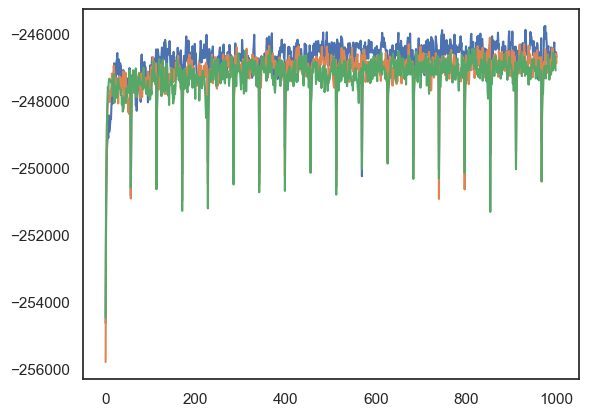

In [344]:
fig, ax = plt.subplots(1, 1)
for i in range(NUM_RUNS):
    sns.lineplot(
        per_name_histories[
            list(per_name_histories.keys())[i]
        ].log_probabilities, ax=ax)

In [345]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
2
CPU times: total: 46.9 ms
Wall time: 1.24 s


In [346]:
from importlib import reload  # Python 3.4+
import hmm_visualization_methods
from hmm_visualization_methods import *
hmm_visualization_methods= reload(hmm_visualization_methods)
from hmm_visualization_methods import *

In [347]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False, discrete=check_peptides, initial_params=initial_params)
    print(i)

0
1
2
CPU times: total: 28.5 s
Wall time: 28.9 s


In [348]:
from hmm_visualization_methods import *


per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-12-13-14-15-16-17-18-21-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (1_run-12-13-14-15-16-17-18-21-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)
Converting graph for model (2_run-12-13-14-15-16-17-18-21-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0) (Delete zero edges)


In [350]:
model.states[14]

{
    "class" : "State",
    "distribution" : {
        "class" : "Distribution",
        "dtype" : "str",
        "name" : "DiscreteDistribution",
        "parameters" : [
            {
                "A" : 0.02626990830379049,
                "C" : 0.010608336458721463,
                "D" : 0.03230937334298109,
                "E" : 0.08314298507691532,
                "F" : 0.011857296892926477,
                "G" : 0.01018267817597662,
                "H" : 0.008333716428574993,
                "I" : 0.02456065920388487,
                "K" : 0.5107688280724624,
                "L" : 0.07204386984009165,
                "M" : 0.014500142975795464,
                "N" : 0.048013754270494896,
                "P" : 0.015345956783907348,
                "Q" : 0.026233850208432885,
                "R" : 0.020097610083760518,
                "S" : 0.029071872675253716,
                "T" : 0.012805162424642417,
                "V" : 0.009484875368926192,
                "W" : 0.00834